# Data Wrangling 
## def
>- cleaning 
>- transforming 
>- organizing 
>- analysis 
>- visualizing 

# _**steps**_

1. Gathering Data  (data import krna ha)
2. Tools to clean Data 
3. How to do kisy (step)
   


In [1]:
# import libraries
import pandas as pd 
import numpy as np 
import seaborn as sns 
import matplotlib as plt


In [2]:
df = sns.load_dataset("titanic")

In [3]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [5]:
df.isnull().sum() /len(df)*100 

survived        0.000000
pclass          0.000000
sex             0.000000
age            19.865320
sibsp           0.000000
parch           0.000000
fare            0.000000
embarked        0.224467
class           0.000000
who             0.000000
adult_male      0.000000
deck           77.216611
embark_town     0.224467
alive           0.000000
alone           0.000000
dtype: float64

In [6]:
df.drop(columns="deck" , inplace=True)

In [7]:
df['age'] = df['age'].fillna(df['age'].mean())

In [8]:
df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])

In [9]:
df['embark_town'] = df['embark_town'].fillna(df['embark_town'].mode()[0])

In [10]:
df.isnull().sum() /len(df)*100 

survived       0.0
pclass         0.0
sex            0.0
age            0.0
sibsp          0.0
parch          0.0
fare           0.0
embarked       0.0
class          0.0
who            0.0
adult_male     0.0
embark_town    0.0
alive          0.0
alone          0.0
dtype: float64

# Outliers Removal

# visualization method:

In [11]:
import seaborn as sns

<Axes: ylabel='age'>

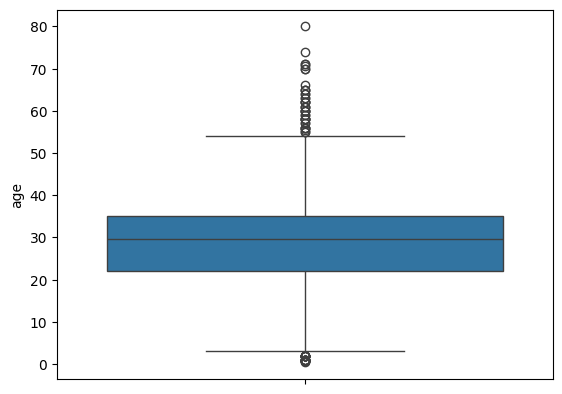

In [12]:
sns.boxplot(data=df, y="age")

<Axes: xlabel='sex', ylabel='age'>

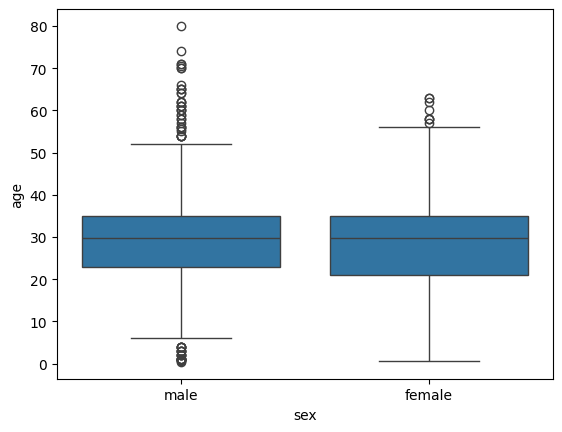

In [13]:
sns.boxplot(data=df, y="age", x="sex")

In [14]:
# IQR Method
#inter quartile range method


In [15]:
Q1 = df["age"].quantile(0.25)
Q3 = df["age"].quantile(0.75)
IQR = Q3 -Q1
IQR
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
#Removing outliers
df = df[(df['age'] > lower_bound) & (df['age'] < upper_bound)]

In [16]:
df.shape

(825, 14)

In [17]:
Q1 = df["fare"].quantile(0.25)
Q3 = df["fare"].quantile(0.75)
IQR = Q3 -Q1
IQR
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
#Removing outliers
df = df[(df['fare'] > lower_bound) & (df['fare'] < upper_bound)]

In [18]:
df.shape

(718, 14)

<Axes: xlabel='age', ylabel='Count'>

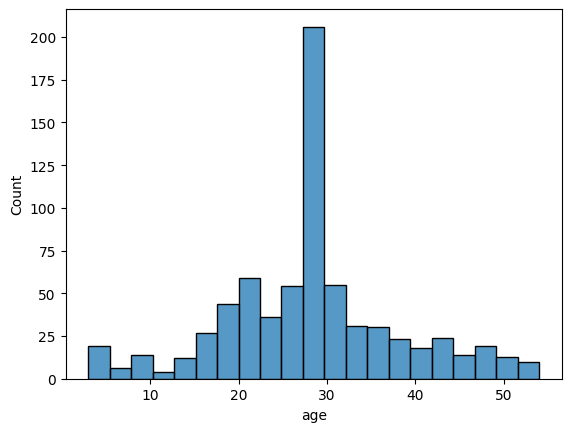

In [19]:
sns.histplot(df['age'])

<Axes: xlabel='fare', ylabel='Count'>

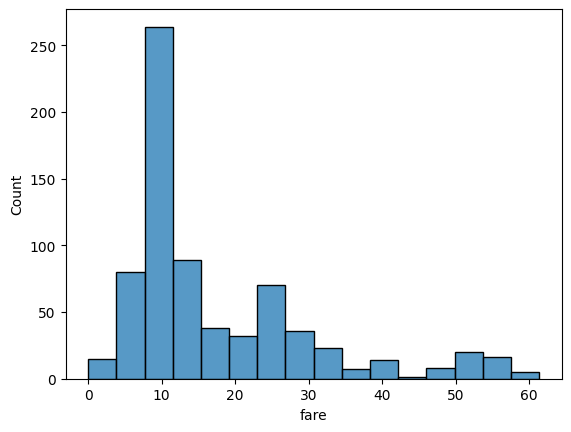

In [20]:
sns.histplot(df['fare'])

In [21]:
# from  scipy import stats
# import numpy as np 

# zscore = np.abs(stats.zscore['age'])
# thershold = 3
# df = df[(z < thershold).all(axis=1)]

In [22]:
df.shape

(718, 14)

In [23]:
#Finding and droping dublicate

#find  dublicates
df.duplicated().sum()

np.int64(103)

In [24]:
df_duplicates = df.duplicated()

In [25]:
df_duplicates.shape

(718,)

In [26]:
df_duplicates.head()

0    False
2    False
3    False
4    False
5    False
dtype: bool

In [27]:
df.drop_duplicates(inplace=True)

In [28]:
df.shape

(615, 14)

# Data Normalization

# Normalization
to bring data at one scale

In [86]:
#pip install scikit-learn 
#1.  import libarires
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

#2. data lana ha 
df


#3. Select Columns to normalize  # numeric
cols_to_normalize = ["age","fare"]

#4. Create the scaler function/ Tool
scaler = MinMaxScaler()

#5.  fit and transform the data on scaler or vice versa
df[cols_to_normalize] = scaler.fit_transform(df[cols_to_normalize])

#5. check the data
df

,survival,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone,family_Size
0,0,3,male,0.372549,1,0,0.118118,S,Third,man,True,Southampton,no,False,1
2,1,3,female,0.450980,0,0,0.129115,S,Third,woman,False,Southampton,yes,True,0
3,1,1,female,0.627451,1,0,0.865114,S,First,woman,False,Southampton,yes,False,1
4,0,3,male,0.627451,0,0,0.131152,S,Third,man,True,Southampton,no,True,0
5,0,3,male,0.523512,0,0,0.137804,Q,Third,man,True,Queenstown,no,True,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
885,0,3,female,0.705882,0,5,0.474509,Q,Third,woman,False,Queenstown,no,False,5
887,1,1,female,0.313725,0,0,0.488765,S,First,woman,False,Southampton,yes,True,0
888,0,3,female,0.523512,1,2,0.382051,S,Third,woman,False,Southampton,no,False,3
889,1,1,male,0.450980,0,0,0.488765,C,First,man,True,Cherbourg,yes,True,0


In [30]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,615.000000,615.000000,615.000000,615.000000,615.000000,615.000000
mean,0.360976,2.469919,0.497584,0.460163,0.365854,0.298831
std,0.480674,0.741063,0.209485,0.894039,0.835572,0.221334
min,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,0.372549,0.000000,0.000000,0.128640
50%,0.000000,3.000000,0.523512,0.000000,0.000000,0.211798
75%,1.000000,3.000000,0.607843,1.000000,0.000000,0.423596
max,1.000000,3.000000,1.000000,5.000000,6.000000,1.000000


In [31]:
#pip install scikit-learn                # standar scaler
#1.  import libarires
import pandas as pd
from sklearn.preprocessing import StandardScaler
#2. data lana ha 
df


#3. Select Columns to normalize  # numeric
cols_to_normalize = ["age","fare"]

#4. Create the scaler function/ Tool
scaler = StandardScaler()

#5.  fit and transform the data on scaler or vice versa
df[cols_to_normalize] = scaler.fit_transform(df[cols_to_normalize])

#5. check the data
df

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone
0,0,3,male,-0.597354,1,0,-0.817136,S,Third,man,True,Southampton,no,False
2,1,3,female,-0.222648,0,0,-0.767410,S,Third,woman,False,Southampton,yes,True
3,1,1,female,0.620441,1,0,2.560585,S,First,woman,False,Southampton,yes,False
4,0,3,male,0.620441,0,0,-0.758201,S,Third,man,True,Southampton,no,True
5,0,3,male,0.123872,0,0,-0.728122,Q,Third,man,True,Queenstown,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
885,0,3,female,0.995147,0,5,0.794372,Q,Third,woman,False,Queenstown,no,False
887,1,1,female,-0.878384,0,0,0.858832,S,First,woman,False,Southampton,yes,True
888,0,3,female,0.123872,1,2,0.376301,S,Third,woman,False,Southampton,no,False
889,1,1,male,-0.222648,0,0,0.858832,C,First,man,True,Cherbourg,yes,True


In [32]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,615.000000,615.000000,6.150000e+02,615.000000,615.000000,6.150000e+02
mean,0.360976,2.469919,3.061688e-16,0.460163,0.365854,-1.213122e-16
std,0.480674,0.741063,1.000814e+00,0.894039,0.835572,1.000814e+00
min,0.000000,1.000000,-2.377209e+00,0.000000,0.000000,-1.351236e+00
25%,0.000000,2.000000,-5.973545e-01,0.000000,0.000000,-7.695610e-01
50%,0.000000,3.000000,1.238725e-01,0.000000,0.000000,-3.935399e-01
75%,1.000000,3.000000,5.267644e-01,1.000000,0.000000,5.641565e-01
max,1.000000,3.000000,2.400296e+00,5.000000,6.000000,3.170505e+00


# Log Transformation

## To Bring data  at one scale

In [33]:
# # pip install scikit-learn                # standar scaler
# #1.  import libarires
# import pandas as pd
# from sklearn.preprocessing import log
# #2. data lana ha 
# df


# #3. Select Columns to normalize  # numeric
# cols_to_normalize = ["age","fare"]

# #4. Create the scaler function/ Tool
# scaler = log()

# #5.  fit and transform the data on scaler or vice versa
# df[cols_to_normalize] = scaler.fit_transform(df[cols_to_normalize])

# #5. check the data
# df

In [55]:
kashti = sns.load_dataset('titanic')
kashti.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [38]:
kashti.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [46]:
import numpy as np 
kashti['age'] = kashti['age'].fillna(kashti['age'].median())
kashti['fare'] = kashti['fare'].fillna(kashti['fare'].median())

# Logrithim Transform 
kashti['age']= np.log(kashti['age'])  # log leny se ap ki values choty scale py ajati hn
kashti['fare']= np.log(kashti['fare'])

kashti.head() # data ki automatically range banata ha log 

c:\Users\server22\AppData\Local\Programs\Python\Python313\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,0.38259,1,0,0.683603,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,0.38259,1,0,1.450832,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,0.38259,0,0,0.727559,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,0.38259,1,0,1.379314,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,0.38259,0,0,0.735091,S,Third,man,True,NaN,Southampton,no,True


<Axes: xlabel='sex', ylabel='fare'>

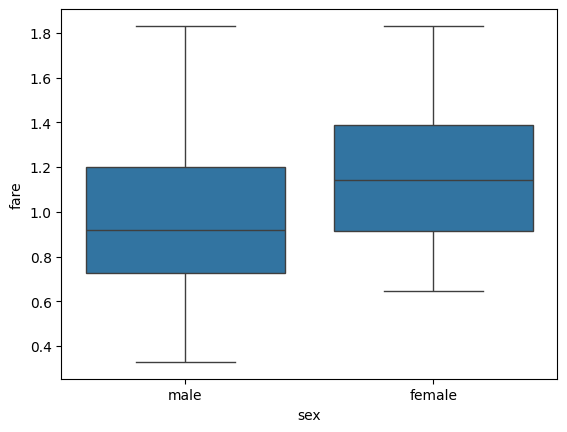

In [49]:
sns.boxplot(data=kashti, x="sex", y="fare")

<Axes: xlabel='age', ylabel='Count'>

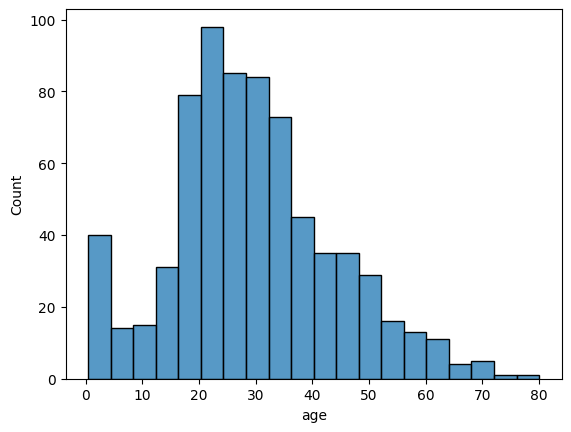

In [56]:
sns.histplot(kashti['age'])

<Axes: xlabel='age', ylabel='Count'>

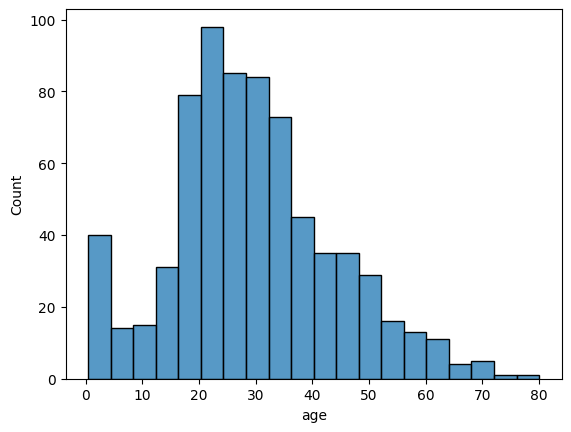

In [57]:
sns.histplot(kashti['age'])

In [61]:
df.columns

Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'embark_town', 'alive',
       'alone', 'family_Size'],
      dtype='object')

# Organizing Data

In [71]:
df ["family_Size"] = df["sibsp"] + df["parch"] # aik new columns add krny ka code ha yh 

<Axes: xlabel='family_Size', ylabel='Count'>

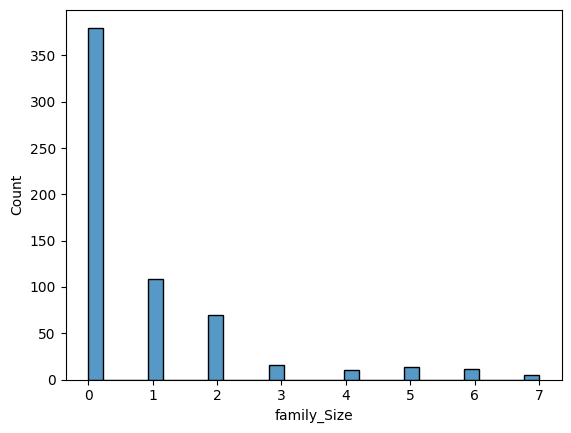

In [72]:
sns.histplot(df["family_Size"])

c:\Users\server22\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 6.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


<Axes: xlabel='sex', ylabel='age'>

c:\Users\server22\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 12.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
c:\Users\server22\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 6.2% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


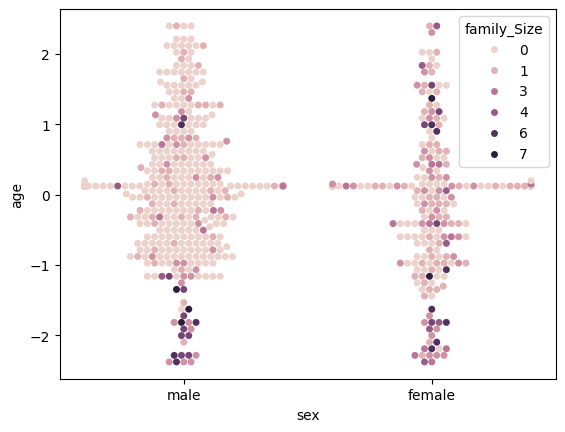

In [74]:
sns.swarmplot(data=df, x= "sex", y="age", hue= "family_Size")

In [ ]:
df = df.rename(columns={"survived": "survival"})  # columns ka name chnage krty hn 
df.columns

Index(['survival', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'embark_town', 'alive',
       'alone', 'family_Size'],
      dtype='object')

In [ ]:
#pivot table
table = pd.pivot_table(df, values='fare',index='pclass', columns= "survival", aggfunc=np.sum) # total karya kitna lia ha 
table

C:\Users\server22\AppData\Local\Temp\ipykernel_4908\2475528391.py:2: FutureWarning: The provided callable <function sum at 0x0000019CC3095580> is currently using DataFrameGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  table = pd.pivot_table(df, values='fare',index='pclass', columns= "survival", aggfunc=np.sum)


survival,0,1
pclass,,
1,47.098956,86.811732
2,-1.053066,13.921025
3,-109.690971,-37.087677


In [81]:
table.to_csv

<bound method NDFrame.to_csv of survival           0          1
pclass                         
1          47.098956  86.811732
2          -1.053066  13.921025
3        -109.690971 -37.087677>

In [ ]:
#pivot table
table = pd.pivot_table(df, values='fare',index='pclass', columns= "survival", aggfunc=np.mean) # average karya 
table

C:\Users\server22\AppData\Local\Temp\ipykernel_4908\245568006.py:2: FutureWarning: The provided callable <function mean at 0x0000019CC3096980> is currently using DataFrameGroupBy.mean. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "mean" instead.
  table = pd.pivot_table(df, values='fare',index='pclass', columns= "survival", aggfunc=np.mean)


survival,0,1
pclass,,
1,1.207666,1.637957
2,-0.015044,0.193348
3,-0.386236,-0.382347


<Axes: xlabel='fare', ylabel='age'>

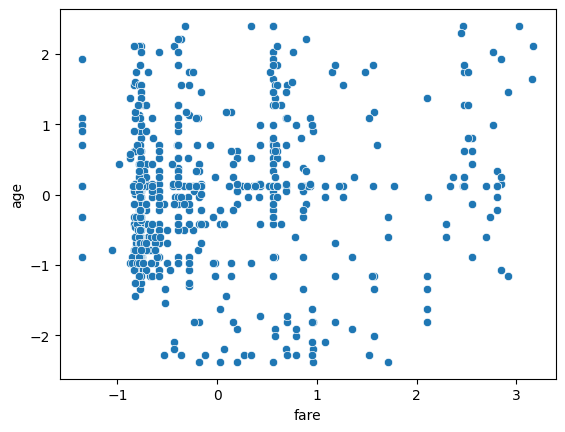

In [83]:
sns.scatterplot(data=df, x='fare', y='age')

In [88]:
df ["family_Size"] = df["sibsp"] + df["parch"]

In [89]:
df.head()

,survival,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone,family_Size
0,0,3,male,0.372549,1,0,0.118118,S,Third,man,True,Southampton,no,False,1
2,1,3,female,0.450980,0,0,0.129115,S,Third,woman,False,Southampton,yes,True,0
3,1,1,female,0.627451,1,0,0.865114,S,First,woman,False,Southampton,yes,False,1
4,0,3,male,0.627451,0,0,0.131152,S,Third,man,True,Southampton,no,True,0
5,0,3,male,0.523512,0,0,0.137804,Q,Third,man,True,Queenstown,no,True,0


# Saving The Data (Wrangled data)

In [90]:
df.to_csv("preprossed_data.csv")

<Axes: xlabel='family_Size', ylabel='age'>

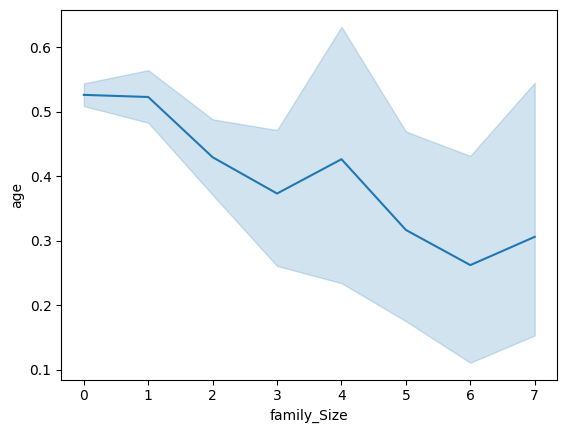

In [ ]:
sns.lineplot(data=df, x='family_Size', y='age') # factorization

<Axes: xlabel='sex', ylabel='age'>

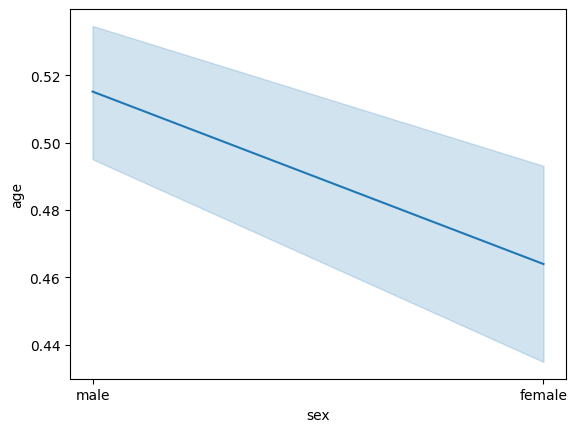

In [92]:
sns.lineplot(data=df, x='sex', y='age') 

<Axes: xlabel='fare', ylabel='age'>

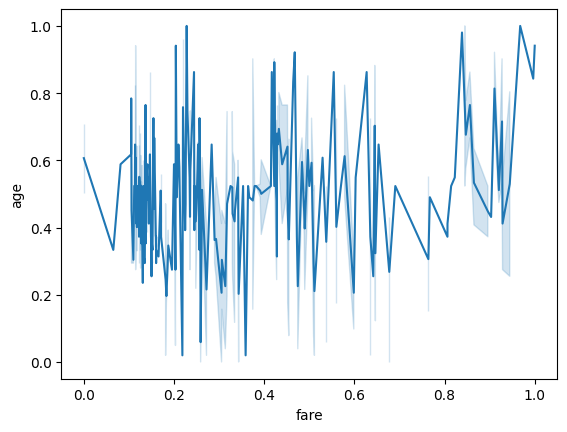

In [93]:
sns.lineplot(data=df, x='fare', y='age') 